# GRU: Melbourne temperature
Adapted from the [GRU forecasting guide](https://sharmasaravanan.medium.com/time-series-forecasting-using-gru-a-step-by-step-guide-b537dc8dcfba) and [GeeksforGeeks](https://www.geeksforgeeks.org/machine-learning/gated-recurrent-unit-networks/).
Run all in Colab and connect Drive.

Changes: Melbourne data, training-only scaling, early stopping, and validation-based tuning. Training: 1981–1986; validation: 1987–1988; test: 1989–1990. Each forecast uses actual temperatures through the previous day.


## 1. Setup


In [1]:
import os
os.environ["TF_DETERMINISTIC_OPS"] = "1"

import hashlib
import io
import json
import urllib.request
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from IPython.display import Markdown, display
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, GRU, Dense
from tensorflow.keras.callbacks import EarlyStopping

try:
    from google.colab import drive
except ImportError:
    OUTPUT = Path("output/gru")
else:
    drive.mount("/content/drive")
    OUTPUT = Path("/content/drive/MyDrive/RNN_Exercise/output/gru")

for folder in ["models", "predictions", "tables", "figures", "histories"]:
    (OUTPUT / folder).mkdir(parents=True, exist_ok=True)

SEED = 42
MAX_EPOCHS = 60
tf.keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()
print("Output:", OUTPUT.resolve())


Mounted at /content/drive
Output: /content/drive/MyDrive/RNN_Exercise/output/gru


## 2. Load and split
Missing dates are forward-filled for inputs only; missing targets are excluded.


Train: before 1987-01-01 | Validation: before 1989-01-01 | Test: 1989-01-01 onward
Missing dates: ['1984-12-31', '1988-12-31']


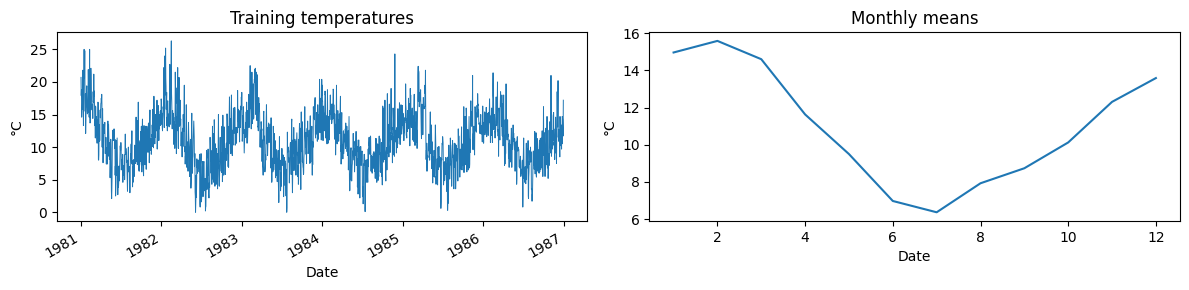

**Pattern:** strong annual seasonality with daily noise; no clear long-term trend.

In [2]:
URL = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/daily-min-temperatures.csv"
with urllib.request.urlopen(URL, timeout=60) as response:
    source = response.read()
raw = pd.read_csv(io.BytesIO(source), parse_dates=["Date"]).set_index("Date").sort_index()
assert raw.index.is_unique and raw["Temp"].notna().all()
assert len(raw) == 3650, "Dataset changed; review split dates."

test_start = raw.index[int(len(raw) * 0.8)]
val_start = raw.index[int(len(raw) * 0.8) - 730]
daily = raw.asfreq("D")["Temp"]
temperature = daily.ffill()
print("Train: before", val_start.date(), "| Validation: before", test_start.date(),
      "| Test:", test_start.date(), "onward")
print("Missing dates:", daily.index[daily.isna()].strftime("%Y-%m-%d").tolist())
(OUTPUT / "dataset.csv").write_bytes(source)

train = daily.loc[daily.index < val_start].dropna()
fig, axes = plt.subplots(1, 2, figsize=(12, 3))
train.plot(ax=axes[0], title="Training temperatures", ylabel="°C", linewidth=0.7)
train.groupby(train.index.month).mean().plot(ax=axes[1], title="Monthly means", ylabel="°C")
plt.tight_layout()
plt.savefig(OUTPUT / "figures/data.png", dpi=150)
plt.show()
display(Markdown("**Pattern:** strong annual seasonality with daily noise; no clear long-term trend."))


## 3. Features and windows
Each row predicts day t using t−1, t−365, past rolling means, and known calendar features. All trials share target dates after a 424-day warm-up.


In [3]:
WINDOWS = [7, 14, 30, 60]
FEATURES = {
    "temperature": ["lag1"],
    "calendar": ["lag1", "sin_year", "cos_year"],
    "seasonal": ["lag1", "lag365"],
    "combined": ["lag1", "lag365", "mean7", "mean30", "sin_year", "cos_year"],
}

def make_features(series):
    past = series.shift(1)
    angle = 2 * np.pi * (series.index.dayofyear - 1) / np.where(series.index.is_leap_year, 366, 365)
    return pd.DataFrame({
        "lag1": past, "lag365": series.shift(365),
        "mean7": past.rolling(7).mean(), "mean30": past.rolling(30).mean(),
        "sin_year": np.sin(angle), "cos_year": np.cos(angle),
    }, index=series.index)

features = make_features(temperature)
positions = np.flatnonzero(daily.notna() & (np.arange(len(daily)) >= 365 + max(WINDOWS) - 1))
dates = daily.index[positions]
is_train = dates < val_start
is_val = (dates >= val_start) & (dates < test_start)
is_test = dates >= test_start
is_dev = ~is_test
y_dev = daily.loc[dates[is_dev]].to_numpy().reshape(-1, 1)
y_val = daily.loc[dates[is_val]].to_numpy()
assert is_test.sum() == 730 and is_val.sum() == 730
assert dates[is_train].max() < dates[is_val].min() < dates[is_test].min()

def prepare(config, fit_end):
    frame = features[FEATURES[config["features"]]]
    x_scaler = MinMaxScaler().fit(frame.loc[frame.index < fit_end].dropna())
    y_scaler = MinMaxScaler().fit(daily.loc[dates[dates < fit_end]].to_numpy().reshape(-1, 1))
    values = x_scaler.transform(frame).astype("float32")
    window = config["window"]
    X = np.array([values[i - window + 1:i + 1] for i in positions])
    assert np.isfinite(X).all()
    return X, y_scaler.transform(y_dev).astype("float32"), x_scaler, y_scaler

def rmse(actual, predicted):
    return float(np.sqrt(np.mean((np.asarray(actual) - np.asarray(predicted)) ** 2)))

def predict(model, X, scaler):
    return scaler.inverse_transform(model.predict(X, verbose=0)).ravel()

print("Targets:", {"train": int(is_train.sum()), "validation": int(is_val.sum()), "test": int(is_test.sum())})


Targets: {'train': 1766, 'validation': 730, 'test': 730}


## 4. GRU
Start with `GRU(50) → GRU(50) → Dense(1)`. Tune units, layers, and learning rate; early stopping restores the best validation weights.


In [4]:
def build_model(config, shape):
    model = Sequential([Input(shape=shape)])
    for layer in range(config["layers"]):
        model.add(GRU(
            config["units"], return_sequences=layer < config["layers"] - 1,
        ))
    model.add(Dense(1))
    model.compile(optimizer=tf.keras.optimizers.Adam(config["lr"], clipnorm=1.0), loss="mse")
    return model

BASE = {"units": 50, "layers": 2, "lr": 0.001}
results = []

def experiment(config, stage):
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)
    X, y, xs, ys = prepare(config, val_start)
    model = build_model(config, X.shape[1:])
    history = model.fit(
        X[is_train], y[:is_train.sum()], validation_data=(X[is_val], y[is_train.sum():]),
        epochs=MAX_EPOCHS, batch_size=64, shuffle=False, verbose=0,
        callbacks=[EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True)],
    )
    trial = f"trial_{len(results) + 1:02d}"
    predicted = predict(model, X[is_val], ys)
    row = {"trial": trial, "stage": stage, **config,
           "epochs": int(np.argmin(history.history["val_loss"]) + 1),
           "val_rmse": rmse(y_val, predicted)}
    results.append(row)
    model.save(OUTPUT / "models" / f"{trial}.keras")
    joblib.dump({"x": xs, "y": ys, "config": config}, OUTPUT / "models" / f"{trial}_scalers.joblib")
    pd.DataFrame(history.history).to_csv(OUTPUT / "histories" / f"{trial}.csv", index=False)
    pd.DataFrame({"Date": dates[is_val], "actual": y_val, "predicted": predicted}).to_csv(
        OUTPUT / "predictions" / f"{trial}_validation.csv", index=False)
    pd.DataFrame(results).to_csv(OUTPUT / "tables/experiments.csv", index=False)
    print(f"{trial}: {config} | validation RMSE = {row['val_rmse']:.4f} °C")


## 5. Compare features, then tune
Select by validation RMSE only. The test set does not guide model settings or epoch count.


trial_01: {'units': 50, 'layers': 2, 'lr': 0.001, 'features': 'temperature', 'window': 7} | validation RMSE = 2.4635 °C
trial_02: {'units': 50, 'layers': 2, 'lr': 0.001, 'features': 'temperature', 'window': 14} | validation RMSE = 2.4169 °C
trial_03: {'units': 50, 'layers': 2, 'lr': 0.001, 'features': 'temperature', 'window': 30} | validation RMSE = 2.4016 °C
trial_04: {'units': 50, 'layers': 2, 'lr': 0.001, 'features': 'temperature', 'window': 60} | validation RMSE = 2.4036 °C
trial_05: {'units': 50, 'layers': 2, 'lr': 0.001, 'features': 'calendar', 'window': 7} | validation RMSE = 2.3636 °C
trial_06: {'units': 50, 'layers': 2, 'lr': 0.001, 'features': 'calendar', 'window': 14} | validation RMSE = 2.3658 °C
trial_07: {'units': 50, 'layers': 2, 'lr': 0.001, 'features': 'calendar', 'window': 30} | validation RMSE = 2.3651 °C
trial_08: {'units': 50, 'layers': 2, 'lr': 0.001, 'features': 'calendar', 'window': 60} | validation RMSE = 2.3656 °C
trial_09: {'units': 50, 'layers': 2, 'lr': 0.0

window,7,14,30,60
features,,,,
calendar,2.3636,2.3658,2.3651,2.3656
combined,2.3527,2.3516,2.3526,2.3553
seasonal,2.4029,2.3995,2.3876,2.3871
temperature,2.4635,2.4169,2.4016,2.4036


trial_17: {'features': 'combined', 'window': 14, 'units': 16, 'layers': 1, 'lr': 0.001} | validation RMSE = 2.3772 °C
trial_18: {'features': 'combined', 'window': 14, 'units': 32, 'layers': 1, 'lr': 0.001} | validation RMSE = 2.3584 °C
trial_19: {'features': 'combined', 'window': 14, 'units': 64, 'layers': 1, 'lr': 0.001} | validation RMSE = 2.3617 °C
trial_20: {'features': 'combined', 'window': 14, 'units': 32, 'layers': 2, 'lr': 0.001} | validation RMSE = 2.3632 °C
trial_21: {'features': 'combined', 'window': 14, 'units': 32, 'layers': 1, 'lr': 0.003} | validation RMSE = 2.3576 °C
trial_22: {'features': 'combined', 'window': 14, 'units': 32, 'layers': 1, 'lr': 0.0003} | validation RMSE = 2.3918 °C


,trial,stage,units,layers,lr,features,window,epochs,val_rmse
13,trial_14,features,50,2,0.0010,combined,14,45,2.3516
14,trial_15,features,50,2,0.0010,combined,30,43,2.3526
12,trial_13,features,50,2,0.0010,combined,7,49,2.3527
15,trial_16,features,50,2,0.0010,combined,60,41,2.3553
20,trial_21,tuning,32,1,0.0030,combined,14,53,2.3576
17,trial_18,tuning,32,1,0.0010,combined,14,42,2.3584
18,trial_19,tuning,64,1,0.0010,combined,14,46,2.3617
19,trial_20,tuning,32,2,0.0010,combined,14,35,2.3632
4,trial_05,features,50,2,0.0010,calendar,7,60,2.3636
6,trial_07,features,50,2,0.0010,calendar,30,39,2.3651


Selected: {'features': 'combined', 'window': 14, 'units': 50, 'layers': 2, 'lr': 0.001} | Refit epochs: 45


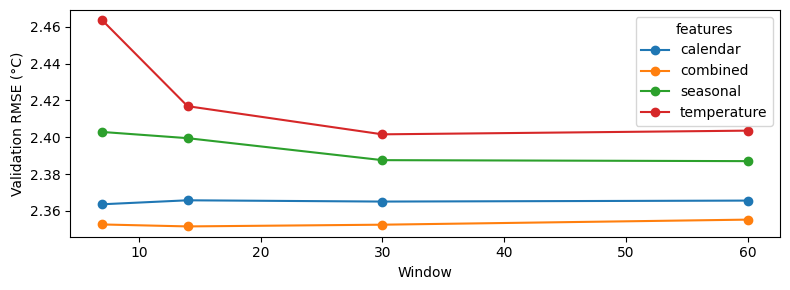

In [5]:
for name in FEATURES:
    for window in WINDOWS:
        experiment({**BASE, "features": name, "window": window}, "features")

feature_results = pd.DataFrame(results)
comparison = feature_results.pivot(index="features", columns="window", values="val_rmse")
display(comparison.round(4))
comparison.to_csv(OUTPUT / "tables/features.csv")

best_pair = min(results, key=lambda row: row["val_rmse"])
settings = [(16, 1, 0.001), (32, 1, 0.001), (64, 1, 0.001),
            (32, 2, 0.001), (32, 1, 0.003), (32, 1, 0.0003)]
for units, layers, lr in settings:
    experiment({"features": best_pair["features"], "window": best_pair["window"],
                "units": units, "layers": layers, "lr": lr}, "tuning")

table = pd.DataFrame(results).sort_values("val_rmse")
display(table.round(4))
best = table.iloc[0].to_dict()
config = {key: best[key] for key in ["features", "window", "units", "layers", "lr"]}
print("Selected:", config, "| Refit epochs:", best["epochs"])

comparison.T.plot(marker="o", figsize=(8, 3), ylabel="Validation RMSE (°C)", xlabel="Window")
plt.tight_layout()
plt.savefig(OUTPUT / "figures/comparison.png", dpi=150)
plt.show()


## 6. Refit and test
Refit on the first 80% for the selected epoch count. Evaluate once against persistence and seasonal baselines.


,RMSE,MAE
model,,
GRU,2.2641,1.7835
Persistence,2.4809,1.9527
Seasonal,3.7404,2.9562
Mean7,2.5955,2.0416


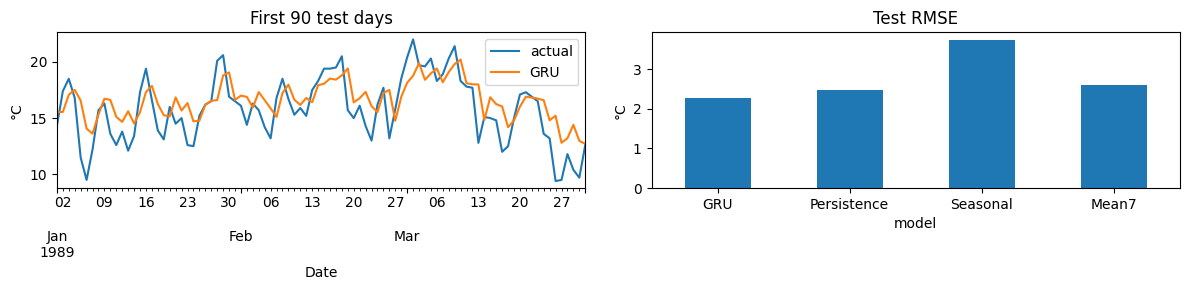

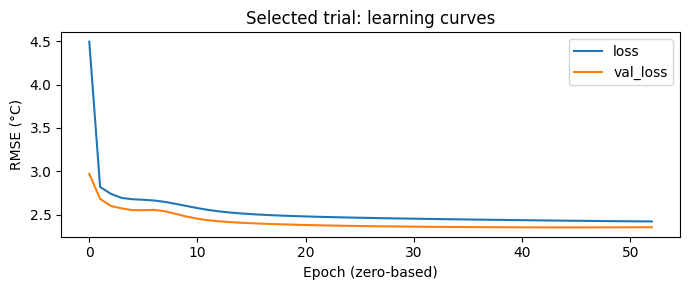

In [6]:
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(SEED)
X, y, x_scaler, y_scaler = prepare(config, test_start)
model = build_model(config, X.shape[1:])
history = model.fit(X[is_dev], y, epochs=int(best["epochs"]), batch_size=64,
                    shuffle=False, verbose=0)
model.save(OUTPUT / "models/best_gru.keras")
joblib.dump({"x": x_scaler, "y": y_scaler, "config": config}, OUTPUT / "models/best_scalers.joblib")
pd.DataFrame(history.history).to_csv(OUTPUT / "histories/refit.csv", index=False)

test_dates = dates[is_test]
actual = daily.loc[test_dates].to_numpy()
predictions = pd.DataFrame({
    "actual": actual,
    "GRU": predict(model, X[is_test], y_scaler),
    "Persistence": features.loc[test_dates, "lag1"].to_numpy(),
    "Seasonal": features.loc[test_dates, "lag365"].to_numpy(),
    "Mean7": features.loc[test_dates, "mean7"].to_numpy(),
}, index=test_dates)
predictions.index.name = "Date"
metrics = pd.DataFrame([
    {"model": name, "RMSE": rmse(actual, predictions[name]),
     "MAE": float(np.mean(np.abs(actual - predictions[name])))}
    for name in predictions.columns if name != "actual"
]).set_index("model")
display(metrics.round(4))
predictions.to_csv(OUTPUT / "predictions/test.csv")
metrics.to_csv(OUTPUT / "tables/test_metrics.csv")

restored = tf.keras.models.load_model(OUTPUT / "models/best_gru.keras")
np.testing.assert_allclose(predict(restored, X[is_test], y_scaler), predictions["GRU"], atol=1e-5)

fig, axes = plt.subplots(1, 2, figsize=(12, 3))
predictions[["actual", "GRU"]].iloc[:90].plot(ax=axes[0], title="First 90 test days", ylabel="°C")
metrics["RMSE"].plot.bar(ax=axes[1], title="Test RMSE", ylabel="°C", rot=0)
plt.tight_layout()
plt.savefig(OUTPUT / "figures/test.png", dpi=150)
plt.show()

curve = pd.read_csv(OUTPUT / "histories" / f"{best['trial']}.csv")
np.sqrt(curve[["loss", "val_loss"]]).mul(
    1 / joblib.load(OUTPUT / "models" / f"{best['trial']}_scalers.joblib")["y"].scale_[0]
).plot(figsize=(7, 3), title="Selected trial: learning curves", xlabel="Epoch (zero-based)", ylabel="RMSE (°C)")
plt.tight_layout()
plt.savefig(OUTPUT / "figures/learning_curve.png", dpi=150)
plt.show()


## 7. Summary
Results below are generated when run. This finite search cannot guarantee the global minimum RMSE; do not retune using the test score.


In [7]:
best_feature = feature_results.groupby("features")["val_rmse"].mean().idxmin()
best_window = int(feature_results.groupby("window")["val_rmse"].mean().idxmin())
gain = 100 * (1 - metrics.loc["GRU", "RMSE"] / metrics.loc["Persistence", "RMSE"])
summary = (
    f"Best average validation settings: **{best_feature}** features and a **{best_window}-day** window; "
    "window length changes the available history, while seasonal features provide annual context. "
    f"The selected GRU achieved **{metrics.loc['GRU', 'RMSE']:.4f} °C test RMSE**, "
    f"versus **{metrics.loc['Persistence', 'RMSE']:.4f} °C** for persistence "
    f"({gain:+.2f}% improvement). "
    "This result applies to the held-out 1989–1990 period; validation comparisons may still favor lucky settings."
)
display(Markdown(summary))
(OUTPUT / "summary.md").write_text(
    "# GRU results\n\n" + summary + "\n\nSelected settings: " + json.dumps(config) +
    f"\nEpochs: {best['epochs']} | Validation RMSE: {best['val_rmse']:.4f} °C\n\n" +
    metrics.to_string() + "\n\nFull experiment table: tables/experiments.csv\n", encoding="utf-8")
metadata = {
    "config": config, "epochs": int(best["epochs"]), "seed": SEED,
    "validation_start": str(val_start.date()), "test_start": str(test_start.date()),
    "dataset_url": URL, "sha256": hashlib.sha256(source).hexdigest(),
    "versions": {"tensorflow": tf.__version__, "numpy": np.__version__, "pandas": pd.__version__},
}
(OUTPUT / "run.json").write_text(json.dumps(metadata, indent=2), encoding="utf-8")
print("Saved:", OUTPUT.resolve())


Best average validation settings: **combined** features and a **30-day** window; window length changes the available history, while seasonal features provide annual context. The selected GRU achieved **2.2641 °C test RMSE**, versus **2.4809 °C** for persistence (+8.74% improvement). This result applies to the held-out 1989–1990 period; validation comparisons may still favor lucky settings.

Saved: /content/drive/MyDrive/RNN_Exercise/output/gru
